---
title: "Quantum Statistics: Fermions and Bosons — Level 2"
short_title: "07 Quantum Statistics"
numbering:
  heading_2: true
  equation: true
---

# Quantum Statistics: Fermions and Bosons

:::{seealso} Math for this topic
- [T-M2: Gaussian, Gamma and quantum-statistics integrals](../math/02-gaussian-gamma-integrals.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
- [T-M1: Counting, probability and Stirling's approximation](../math/01-counting-probability-stirling.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered, apart from the Fermi energy in the modern-physics chapters |
| **2** | **Schroeder, ch. 7** | **Fermi gas, Bose–Einstein condensation, blackbody radiation, the Debye model** |
| 3 | Pathria, ch. 5–8 | Formal quantum statistics, ideal Bose and Fermi systems, polylogarithm expansions |

The new skill at this level: counting occupation numbers of single-particle states instead of particles, which builds the exclusion principle and boson bunching into thermodynamics

Math for this topic: T-M2 (Gamma and Bose–Fermi integrals), mechanics M1 (Taylor series) and T-M1 (probability).
:::

Workbook example ladder: the Fermi energy of electrons in a metal → the critical temperature for Bose–Einstein condensation → the specific-heat cusp at that temperature. Read quantum topics 1 and 7 first if you can (wave functions in a box, identical particles). Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## When Does Quantum Statistics Matter?

Topic 6's ideal gas assumed $Z = Z_1^N/N!$, which counts correctly only if no two particles ever share a single-particle state. That holds when the number of available states (roughly $V/v_Q$, with $v_Q = \lambda^3$ the thermal quantum volume) far exceeds $N$:

$$
\frac{V}{N}\gg v_Q = \left(\frac{h}{\sqrt{2\pi mkT}}\right)^3 .
$$ (eq-classical-condition)

Helium at room conditions passes by a factor of $3\times10^5$ (topic 6). Electrons in a metal fail spectacularly: they are 7000 times lighter and $10^3$ times denser than a gas, so $V/N\ll v_Q$ even at room temperature. Light from a hot oven fails too, because photons can be created freely and their number adjusts to fill the low-energy modes.

## Occupation Numbers

Change the bookkeeping. Instead of asking which state each particle is in, ask how many particles occupy each **single-particle state** (orbital) of energy $\epsilon$. Treat one orbital as a system that exchanges particles and energy with the rest of the gas at temperature $T$ and chemical potential $\mu$. The probability of holding $n$ particles carries the **Gibbs factor** $e^{-n(\epsilon - \mu)/kT}$ (the grand-canonical generalization of the Boltzmann factor, topic 5's look-ahead).

- **Fermions** (electrons, protons, neutrons, ³He): $n = 0$ or $1$ only. Summing two terms,

$$
\bar n_{\text{FD}} = \frac{1}{e^{(\epsilon - \mu)/kT} + 1} .
$$ (eq-fermi-dirac)

- **Bosons** (photons, ⁴He, ⁸⁷Rb): $n = 0, 1, 2, \ldots$. Summing a geometric series,

$$
\bar n_{\text{BE}} = \frac{1}{e^{(\epsilon - \mu)/kT} - 1} .
$$ (eq-bose-einstein)

When $\epsilon - \mu\gg kT$ both reduce to the Boltzmann form $\bar n = e^{-(\epsilon - \mu)/kT}$, the classical limit where every orbital is nearly empty.

In [2]:
# Derive both occupancies from the grand sum over n for one orbital
x = sp.symbols("x", positive=True)       # x = (epsilon - mu)/kT
Zf = 1 + sp.exp(-x)
Zb = 1 / (1 - sp.exp(-x))     # sum over n of exp(-n x), a geometric series (x > 0)
nf = sp.simplify(-sp.diff(sp.log(Zf), x))
nb = sp.simplify(-sp.diff(sp.log(Zb), x))
display(Math(r"\bar n_{\rm FD} = " + sp.latex(nf) + r",\qquad \bar n_{\rm BE} = " + sp.latex(nb)))

<IPython.core.display.Math object>

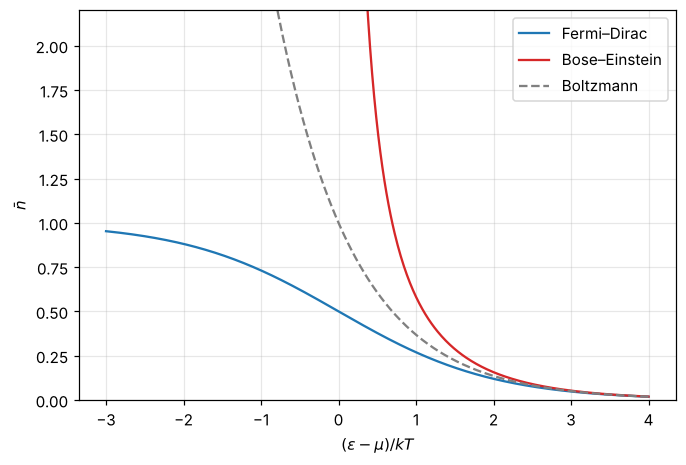

In [3]:
#| label: fig-occupancies
#| caption: "Average occupancy of an orbital versus (ε − μ)/kT. Fermi–Dirac (blue) never exceeds 1; Bose–Einstein (red) diverges as ε → μ, which is why μ must stay below the lowest energy for bosons. All three agree once ε − μ is a few kT."
xx = np.linspace(-3, 4, 400); xb = np.linspace(0.05, 4, 300)
fig, ax = plt.subplots()
ax.plot(xx, 1 / (np.exp(xx) + 1), label="Fermi–Dirac")
ax.plot(xb, 1 / np.expm1(xb), color="tab:red", label="Bose–Einstein")
ax.plot(xx, np.exp(-xx), "--", color="gray", label="Boltzmann")
ax.set_ylim(0, 2.2); ax.set_xlabel("$(\\epsilon - \\mu)/kT$"); ax.set_ylabel("$\\bar n$"); ax.legend(); plt.show()

## The Degenerate Fermi Gas

At $T = 0$ fermions fill the lowest orbitals one per state (two per spatial state, counting spin), up to the **Fermi energy** $\epsilon_F$. Counting particle-in-a-box states in a sphere of momentum space,

$$
\epsilon_F = \frac{h^2}{8m}\left(\frac{3N}{\pi V}\right)^{2/3} ,
$$ (eq-fermi-energy)

and the **density of states** (orbitals per unit energy) is

$$
g(\epsilon) = \frac{3N}{2\epsilon_F^{3/2}}\sqrt\epsilon .
$$ (eq-dos-3d)

The average energy at $T = 0$ is $\tfrac35\epsilon_F$ per particle, far above $kT$. The electrons cannot slow down because the lower states are full, and this zero-temperature energy pushes outward as **degeneracy pressure**, $P = \tfrac25(N/V)\epsilon_F$, which holds up white dwarfs and neutron stars.

::::{prf:example} Level 2 rung: the Fermi energy of copper
:label: ex-copper-fermi

Copper has one conduction electron per atom and $8.47\times10^{28}$ atoms per m³. Find $\epsilon_F$, the Fermi temperature $T_F = \epsilon_F/k$ and the Fermi speed.

:::{dropdown} Solution
From {eq}`eq-fermi-energy`, $\epsilon_F = 7.0$ eV, $T_F = 82\,000$ K and $v_F = \sqrt{2\epsilon_F/m} = 1.6\times10^6$ m/s (computed below). Room temperature is 0.4% of $T_F$, so the conduction electrons are almost completely degenerate.
:::
::::

In [4]:
m_e = 9.109e-31
n_Cu = 8.47e28
eF = h**2 / (8 * m_e) * (3 * n_Cu / np.pi)**(2 / 3)
display(Math(rf"\epsilon_F = {eF / eV:.2f}\ \text{{eV}},\quad T_F = {eF / k_B:.0f}\ \text{{K}},\quad v_F = " + sp.latex(sp.Float(np.sqrt(2 * eF / m_e), 3)) + r"\ \text{m/s}"))

<IPython.core.display.Math object>

### Small temperatures

At $T > 0$ only electrons within a few $kT$ of $\epsilon_F$ can move into empty states above. A fraction $\sim kT/\epsilon_F$ of them each gain $\sim kT$, so the thermal energy is $\sim NkT^2/T_F$ and the heat capacity is linear in $T$:

$$
C_V = \frac{\pi^2}{2}Nk\frac{kT}{\epsilon_F} .
$$ (eq-sommerfeld-cv)

(The $\pi^2/2$ comes from the Sommerfeld expansion, which Pathria does carefully.) This solved a 19th-century puzzle: if electrons in metals were a classical gas, they would add $\tfrac32k$ each to the heat capacity, and they plainly do not.

To find $\mu(T)$, fix $N = \int_0^\infty g(\epsilon)\bar n_{\text{FD}}(\epsilon)\,d\epsilon$ and solve for $\mu$, which the next cell does numerically.

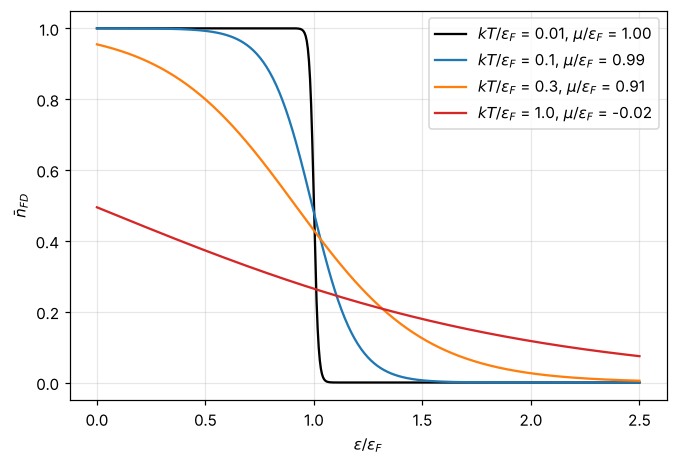

In [5]:
#| label: fig-fermi-dirac-T
#| caption: "Fermi–Dirac distributions for an electron gas at kT/ε_F = 0.01, 0.1, 0.3 and 1, with μ found numerically so the particle number stays fixed. At low T only a band about kT wide around ε_F is affected; by kT ≈ ε_F the distribution is nearly classical and μ has dropped below zero."
from scipy.integrate import quad
def mu_of_T(t):            # in units of eps_F; N fixed: integral of (3/2) sqrt(e) n(e) de = 1
    f = lambda mu: quad(lambda e: 1.5 * np.sqrt(e) / (np.exp((e - mu) / t) + 1), 0, max(mu, 0) + 50 * t + 1, limit=200)[0] - 1
    return brentq(f, -10, 1.5)
e = np.linspace(0, 2.5, 500)
fig, ax = plt.subplots()
for t, col in [(0.01, "k"), (0.1, "tab:blue"), (0.3, "tab:orange"), (1.0, "tab:red")]:
    mu = mu_of_T(t)
    ax.plot(e, 1 / (np.exp((e - mu) / t) + 1), color=col, label=f"$kT/\\epsilon_F$ = {t}, $\\mu/\\epsilon_F$ = {mu:.2f}")
ax.set_xlabel("$\\epsilon/\\epsilon_F$"); ax.set_ylabel("$\\bar n_{FD}$"); ax.legend(); plt.show()

## Blackbody Radiation

Photons are bosons whose number is not conserved, so in equilibrium $\mu = 0$. Each electromagnetic mode of frequency $f$ in a box is an orbital, and counting modes (two polarizations, a sphere in $\vec k$-space) gives the **Planck spectrum** of energy per unit volume per unit frequency:

$$
u(f) = \frac{8\pi hf^3}{c^3}\frac{1}{e^{hf/kT} - 1} .
$$ (eq-planck)

Integrating with T-M2's Bose integral ($\Gamma(4)\zeta(4) = \pi^4/15$) gives the total energy density $U/V = \dfrac{8\pi^5(kT)^4}{15(hc)^3}$, and the power radiated per unit area of a black surface is $\sigma T^4$ with

$$
\sigma = \frac{2\pi^5k^4}{15h^3c^2} = 5.67\times10^{-8}\ \text{W/(m}^2\text{K}^4) .
$$ (eq-stefan-boltzmann)

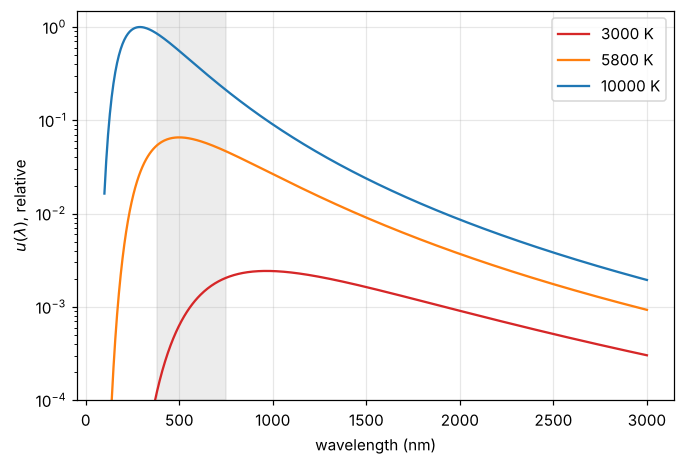

<IPython.core.display.Math object>

In [6]:
#| label: fig-planck-spectrum
#| caption: "Planck spectra for 3000 K (an incandescent filament), 5800 K (the Sun's surface) and 10 000 K, per unit wavelength. The peak follows Wien's law λ_max T = 2.90 mm·K; the gray band is visible light. Only the hottest spectrum peaks in the visible-blue, and the Sun peaks near green."
c = 2.998e8
lam = np.linspace(100e-9, 3000e-9, 600)
def u_lam(lam, T):
    return 8 * np.pi * h * c / lam**5 / np.expm1(h * c / (lam * k_B * T))
fig, ax = plt.subplots()
for T, col in [(3000, "tab:red"), (5800, "tab:orange"), (10000, "tab:blue")]:
    ax.plot(lam * 1e9, u_lam(lam, T) / u_lam(2.898e-3 / 10000, 10000), color=col, label=f"{T} K")
ax.axvspan(380, 750, color="gray", alpha=0.15)
ax.set_yscale("log"); ax.set_ylim(1e-4, 1.5)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("$u(\\lambda)$, relative"); ax.legend(); plt.show()
sigma = 2 * np.pi**5 * k_B**4 / (15 * h**3 * c**2)
display(Math(rf"\sigma = " + sp.latex(sp.Float(sigma, 4)) + r"\ \text{W/(m}^2\text{K}^4)"))

## The Debye Solid

Topic 3's Einstein solid gave every atom the same vibration frequency, and its heat capacity fell exponentially at low $T$. Real solids fall like $T^3$. Debye's fix: treat lattice vibrations as sound waves (phonons, bosons with $\mu = 0$), exactly like photons but with the sound speed $c_s$ and three polarizations, and cut the spectrum off at a maximum frequency so the number of modes is $3N$. The cutoff defines the **Debye temperature** $T_D$. At low $T$, only long-wavelength modes are excited, the Planck calculation applies, and

$$
C_V = \frac{12\pi^4}{5}Nk\left(\frac{T}{T_D}\right)^3\qquad(T\ll T_D) .
$$ (eq-debye-t3)

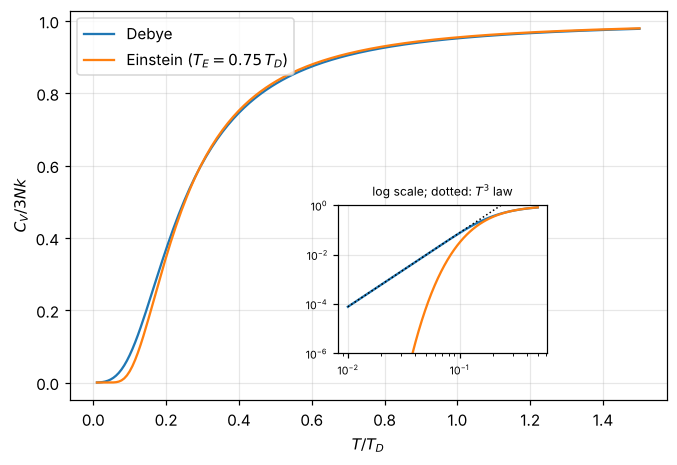

In [7]:
#| label: fig-debye-einstein
#| caption: "Heat capacity per atom of the Debye model (blue) and an Einstein model (orange, with T_E chosen as 0.75 T_D for comparison). Both reach the Dulong–Petit value 3k at high T. At low T (inset, log scale) the Debye curve follows T³ while the Einstein curve collapses exponentially; measured insulators follow Debye."
def c_debye(t):            # t = T/T_D, result in units of 3Nk
    I, _ = quad(lambda x: x**4 * np.exp(x) / np.expm1(x)**2, 0, 1 / t)
    return 3 * t**3 * I
def c_einstein(t, tE=0.75):
    x = tE / t
    return x**2 * np.exp(x) / np.expm1(x)**2
t = np.linspace(0.01, 1.5, 200)
fig, ax = plt.subplots()
ax.plot(t, [c_debye(ti) for ti in t], label="Debye")
ax.plot(t, c_einstein(t), label="Einstein ($T_E = 0.75\\,T_D$)")
ax.set_xlabel("$T/T_D$"); ax.set_ylabel("$C_V/3Nk$"); ax.legend(loc="upper left")
ins = ax.inset_axes([0.45, 0.12, 0.35, 0.38])
tl = np.logspace(-2, -0.3, 60)
ins.loglog(tl, [c_debye(ti) for ti in tl]); ins.loglog(tl, c_einstein(tl)); ins.loglog(tl, 4 * np.pi**4 / 5 * tl**3, "k:", lw=1)
ins.set_ylim(1e-6, 1); ins.set_title("log scale; dotted: $T^3$ law", fontsize=8); ins.tick_params(labelsize=7)
plt.show()

## Bose–Einstein Condensation

For bosons with conserved number (atoms), lower the temperature at fixed density. The chemical potential rises toward the lowest orbital energy. The number of atoms the *excited* states can hold, $\int g(\epsilon)\,d\epsilon/(e^{\epsilon/kT} - 1)$ at its largest ($\mu = 0$), is a Bose integral (T-M2, $\Gamma(\tfrac32)\zeta(\tfrac32)$):

$$
N_{\text{excited}}\le2.612\,\frac{V}{v_Q} .
$$

When $N$ exceeds that, the excess has nowhere to go but the ground state. The **critical temperature** is where $N = 2.612\,V/v_Q$:

$$
kT_c = 0.527\,\frac{h^2}{2\pi m}\left(\frac NV\right)^{2/3} ,
$$ (eq-bec-tc)

and below it the fraction in the ground state is $N_0/N = 1 - (T/T_c)^{3/2}$. A macroscopic number of atoms in one quantum state is the **Bose–Einstein condensate**, first made in 1995 with rubidium-87 at about 170 nK.

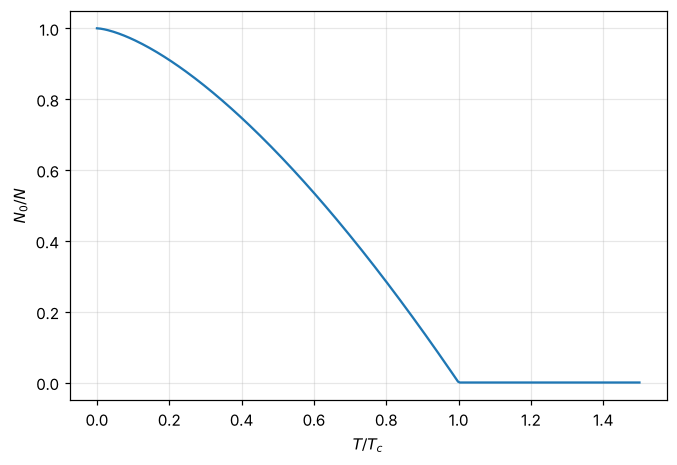

<IPython.core.display.Math object>

In [8]:
#| label: fig-bec-fraction
#| caption: "Condensate fraction of an ideal Bose gas versus temperature, N₀/N = 1 − (T/T_c)^(3/2). It switches on sharply at T_c. The heat capacity (Level 3) has a cusp at the same point."
tt = np.linspace(0, 1.5, 300)
fig, ax = plt.subplots()
ax.plot(tt, np.where(tt < 1, 1 - tt**1.5, 0))
ax.set_xlabel("$T/T_c$"); ax.set_ylabel("$N_0/N$"); plt.show()
m_Rb = 87 * 1.6605e-27
n_Rb = 2.5e19     # atoms per m^3
Tc = 0.527 * h**2 / (2 * np.pi * m_Rb * k_B) * n_Rb**(2 / 3)
display(Math(rf"T_c(^{{87}}\text{{Rb}},\ n = 2.5\times10^{{19}}\ \text{{m}}^{{-3}}) = {Tc * 1e9:.0f}\ \text{{nK}}"))

## Looking Ahead to Level 3

Pathria writes the Bose and Fermi integrals for general fugacity $z = e^{\mu/kT}$ as polylogarithms, $\sum_\ell z^\ell/\ell^s$, and expands them in $z$ (nearly classical gases) or in $1/\ln z$ (degenerate ones). The ideal Bose gas heat capacity rises as $T^{3/2}$ below $T_c$, peaks at $1.93Nk$ at $T_c$ with a discontinuous slope, then falls to $\tfrac32Nk$: a phase transition in a gas with no interactions at all.

## Exercises

### Exercises

1. Find the Fermi energy and Fermi temperature of the electrons in a white dwarf with density $10^9$ kg/m³ (assume two nucleons per electron). Are they degenerate at an interior temperature of $10^7$ K? Are they relativistic?
2. Show that the average energy of a $T = 0$ Fermi gas is $\tfrac35\epsilon_F$ per particle, using {eq}`eq-dos-3d`.
3. Use Wien's law to find the peak wavelength of the cosmic microwave background (2.725 K) and of a human body (310 K).
4. Estimate the power radiated by a person (surface 1.8 m², skin at 306 K, emissivity ≈ 1) into a 293 K room, net of what they absorb.
5. Liquid ⁴He has density 145 kg/m³. Treating it as an ideal Bose gas, estimate $T_c$ and compare with its superfluid transition at 2.17 K.

:::{dropdown} Hints
1. Electron density $n = \rho/(2m_p)$; then {eq}`eq-fermi-energy`. Compare $p_F = \sqrt{2m\epsilon_F}$ with $m_ec$.
2. $\bar E = \int_0^{\epsilon_F}\epsilon\,g(\epsilon)\,d\epsilon/N$.
3. $\lambda_{\max}T = 2.90$ mm·K.
4. $P_{\text{net}} = \sigma A(T_s^4 - T_r^4)$.
5. {eq}`eq-bec-tc` with $m = 4$ u and $n = \rho/m$.
:::

:::{dropdown} Answers
1. $n = 3.0\times10^{35}$ m⁻³, $\epsilon_F\approx 0.16$ MeV (nonrelativistic formula), $T_F\approx 1.9\times10^9$ K: highly degenerate. $p_Fc\approx 0.41$ MeV is comparable to $m_ec^2 = 0.511$ MeV, so the electrons are mildly relativistic, and the nonrelativistic formula overestimates $\epsilon_F$.
2. $\int_0^{\epsilon_F}\epsilon^{3/2}d\epsilon = \tfrac25\epsilon_F^{5/2}$; with the prefactor, $\bar E = \tfrac32\cdot\tfrac25\epsilon_F = \tfrac35\epsilon_F$.
3. CMB: 1.06 mm (microwaves). Body: 9.4 μm (thermal infrared).
4. $5.67\times10^{-8}\times1.8\times(306^4 - 293^4)\approx 140$ W. (Clothing cuts this a lot.)
5. $T_c\approx 3.1$ K. Close to 2.17 K: the ideal-gas model captures the physics, and interactions in the liquid lower $T_c$.
:::

## Summary

- Quantum statistics matters when $V/N\lesssim v_Q$: dense, cold or light particles, and always for photons and phonons.
- Occupancies: $\bar n = 1/(e^{(\epsilon - \mu)/kT}\pm1)$, $+$ for fermions, $-$ for bosons; both reduce to Boltzmann when $\epsilon - \mu\gg kT$.
- Degenerate fermions fill states to $\epsilon_F$; only a $kT/\epsilon_F$ fraction is thermally active, so $C\propto T$. Degeneracy pressure supports white dwarfs.
- Photons ($\mu = 0$): Planck spectrum, $\sigma T^4$. Phonons: Debye's $T^3$ heat capacity.
- Bosons with fixed $N$ condense below $T_c$, with condensate fraction $1 - (T/T_c)^{3/2}$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.